# Rick and Morty, em emoções · Portfolio Night 2026 · São Paulo

Para o Portfolio Night, adaptei um estudo autoral iniciado no Kaggle para explicar uma pergunta: até onde um dicionário de sentimentos consegue descrever o vocabulário de Rick and Morty? Esta versão reúne o método, uma comparação visual e um exemplo dos seus limites. O notebook Análise de Sentimentos preserva a exploração original; esta atualização usa o mesmo corpus.

**Autora:** Isabel Gonçalves Cruz · [GitHub](https://github.com/bellDataSc/Analise-de-Sentimentos)

**Unidade de análise:** ocorrência de palavra nas falas disponíveis. As taxas descrevem associações lexicais; não medem o estado psicológico de um personagem nem a intenção de uma fala.

## Perguntas que orientam a leitura

1. Quanto do vocabulário os léxicos cobrem e onde concordam?
2. O perfil por personagem depende do volume e de poucas palavras?
3. Quais episódios merecem inspeção quando os métodos discordam?

A avaliação humana, a regra de negação e a comparação com modelo contextual continuam como extensões. Não há métricas de acurácia ou F1 nesta entrega.

## Preparação técnica

As entradas são escolhidas pelos quatro nomes de arquivo documentados. O leitor rejeita esquemas inválidos e valores conflitantes. Apóstrofos retos e curvos são normalizados; contrações e marcadores como `not` são preservados. As funções abaixo sustentam todas as tabelas.

Todas as funções estão neste arquivo. No Kaggle, mantenha anexados os datasets de roteiros e léxicos. Fora do Kaggle, a célula de dados baixa automaticamente a versão 1 de cada fonte pública e verifica os hashes. As saídas são geradas durante a execução e também aparecem abaixo.

In [1]:
# No Kaggle, estas bibliotecas já costumam estar disponíveis.
# Em outro ambiente, esta célula instala somente as dependências ausentes.
import importlib.util
import subprocess
import sys

if sys.version_info < (3, 11):
    raise RuntimeError("Use Python 3.11 ou posterior.")
requirements = {
    "numpy": "numpy==2.3.5",
    "pandas": "pandas==2.2.3",
    "matplotlib": "matplotlib==3.10.8",
    "IPython": "ipython>=8",
}
missing = [requirement for module, requirement in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])


In [2]:
# Funções usadas neste notebook: leitura, validação, tokenização e métricas
"""Regras compartilhadas; nenhuma função precisa de credenciais ou rede."""

from itertools import combinations
from pathlib import Path
import re

import numpy as np
import pandas as pd

EMOTIONS = ["anger", "anticipation", "disgust", "fear", "joy", "sadness", "surprise", "trust"]
CATEGORIES = EMOTIONS + ["positive", "negative"]
PT = dict(zip(EMOTIONS, ["raiva", "expectativa", "nojo", "medo", "alegria", "tristeza", "surpresa", "confiança"]))
CATEGORY_ALIASES = {v: k for k, v in PT.items()} | {"positivo": "positive", "negativo": "negative"}


def normalize_text(value):
    return str(value).replace("’", "'").replace("‘", "'").casefold()


def tokenize(text):
    """Uma ocorrência por token; preserva contrações e marcadores de negação."""
    if pd.isna(text):
        return []
    return re.findall(r"[^\W\d_]+(?:'[^\W\d_]+)*", normalize_text(text))


def read_table(path):
    """CSV/TSV com cabeçalho; falha em linhas malformadas."""
    path = Path(path)
    sep = "\t" if path.suffix.lower() == ".tsv" else ","
    try:
        return pd.read_csv(path, sep=sep, encoding="utf-8-sig", on_bad_lines="error")
    except UnicodeDecodeError:
        # Afinn.csv, na fonte usada pelo projeto, requer Latin-1.
        return pd.read_csv(path, sep=sep, encoding="latin-1", on_bad_lines="error")


def normalize_lexicon(frame, kind):
    """AFINN: word/value. NRC/Bing: longo, longo 0/1 ou largo 0/1."""
    kind = kind.upper()
    if kind not in {"AFINN", "NRC", "BING"}:
        raise ValueError(f"Léxico desconhecido: {kind}")
    df = frame.copy()
    df.columns = [str(c).strip().casefold() for c in df.columns]
    if df.columns.duplicated().any() or "word" not in df:
        raise ValueError("Esperado cabeçalho único com coluna word.")
    if df["word"].isna().any():
        raise ValueError("Há palavra ausente no léxico.")
    df["word"] = df["word"].map(normalize_text).str.strip()
    if df["word"].eq("").any():
        raise ValueError("Há palavra vazia no léxico.")
    if kind == "AFINN":
        col = next((c for c in ("value", "score", "valor") if c in df), None)
        if col is None:
            raise ValueError("AFINN precisa de word e value/score.")
        score = pd.to_numeric(df[col], errors="raise")
        if not (score.notna() & np.isfinite(score) & score.between(-5, 5) & score.eq(score.round())).all():
            raise ValueError("AFINN: os valores devem ser inteiros de -5 a 5.")
        out = pd.DataFrame({"word": df["word"], "category": "valence", "value": score})
        if out.groupby("word")["value"].nunique().gt(1).any():
            raise ValueError("AFINN tem valores conflitantes para a mesma palavra.")
        return out.drop_duplicates(["word", "category"]).reset_index(drop=True)

    category_col = next((c for c in ("sentiment", "emotion", "category", "categoria") if c in df), None)
    if category_col:
        if df[category_col].isna().any():
            raise ValueError("Categoria ausente no léxico.")
        out = df[["word", category_col]].rename(columns={category_col: "category"})
        flag = next((c for c in ("association", "associated", "flag", "value", "valor") if c in df), None)
        if flag:
            values = pd.to_numeric(df[flag], errors="raise")
            if not values.isin([0, 1]).all():
                raise ValueError("Associações devem ser 0 ou 1.")
            out = out.loc[values.eq(1)].copy()
    else:
        cols = [c for c in df if c in CATEGORIES or c in CATEGORY_ALIASES]
        if not cols:
            raise ValueError("Não há categorias reconhecidas no formato largo.")
        for col in cols:
            df[col] = pd.to_numeric(df[col], errors="raise")
            if not df[col].isin([0, 1]).all():
                raise ValueError("Colunas do formato largo devem conter 0 ou 1.")
        out = df.melt(id_vars="word", value_vars=cols, var_name="category", value_name="association")
        out = out.loc[out["association"].eq(1), ["word", "category"]].copy()
    out["category"] = out["category"].astype(str).str.strip().str.casefold().replace(CATEGORY_ALIASES)
    allowed = {"positive", "negative"} if kind == "BING" else set(CATEGORIES)
    unknown = set(out["category"]) - allowed
    if unknown:
        raise ValueError(f"Categorias não reconhecidas: {sorted(unknown)}")
    out["value"] = 1.0
    return out[["word", "category", "value"]].drop_duplicates(["word", "category"]).reset_index(drop=True)


def prepare_corpus(raw, character_map=None):
    """Mantém ordem, ID de origem e variantes; exclusões ficam registradas."""
    names = {"season no.": "season", "episode no.": "episode", "episode name": "episode_title",
             "name": "character_original", "line": "text", "index": "source_id"}
    df = raw.rename(columns=names).copy()
    required = ["season", "episode", "character_original", "text"]
    missing = set(required) - set(df)
    if missing:
        raise ValueError(f"Colunas ausentes no roteiro: {sorted(missing)}")
    df["line_id"] = np.arange(len(df))
    if "source_id" not in df:
        df["source_id"] = df["line_id"]
    if "episode_title" not in df:
        df["episode_title"] = ""
    missing_text = df["text"].isna()
    blank_text = ~missing_text & df["text"].astype("string").str.strip().eq("").fillna(False)
    excluded = df.loc[missing_text | blank_text, ["line_id", "source_id"]].copy()
    excluded["reason"] = np.where(missing_text.loc[excluded.index], "texto_ausente", "texto_vazio")
    df = df.loc[~(missing_text | blank_text)].copy()
    for col in ("season", "episode"):
        values = pd.to_numeric(df[col], errors="raise")
        if not (values.notna() & np.isfinite(values) & values.gt(0) & values.eq(values.round())).all():
            raise ValueError(f"{col}: esperado inteiro positivo.")
        df[col] = values.astype(int)
    df["character_original"] = df["character_original"].fillna("Sem personagem").astype(str).str.strip()
    df["character_original"] = df["character_original"].replace("", "Sem personagem")
    df["character"] = df["character_original"].replace(character_map or {})
    df["tokens"] = df["text"].map(tokenize)
    df["n_tokens"] = df["tokens"].map(len)
    token_rows = df[["line_id", "season", "episode", "character", "tokens"]].explode("tokens")
    token_rows = token_rows.dropna(subset=["tokens"]).rename(columns={"tokens": "word"}).reset_index(drop=True)
    token_rows["token_id"] = np.arange(len(token_rows))
    duplicates = df.duplicated(["season", "episode", "character_original", "text"], keep=False)
    quality = {"input_rows": len(raw), "retained_lines": len(df), "excluded_lines": len(excluded),
               "zero_token_lines": int(df["n_tokens"].eq(0).sum()), "tokens": len(token_rows),
               "duplicate_candidate_rows": int(duplicates.sum()), "duplicates_removed": 0,
               "missing_character_lines": int(df["character_original"].eq("Sem personagem").sum())}
    return df, token_rows, excluded, quality


def polarity_scores(lexicon):
    if set(lexicon["category"]) == {"valence"}:
        return lexicon.set_index("word")["value"].astype(float)
    sub = lexicon.loc[lexicon["category"].isin(["positive", "negative"])].copy()
    sub["score"] = sub["category"].map({"positive": 1.0, "negative": -1.0})
    # Uma palavra com ambas as polaridades é coberta, com saldo zero.
    return sub.groupby("word")["score"].sum()


def score_lines(corpus, lexicons):
    out = corpus.copy()
    for name, lexicon in lexicons.items():
        scores = polarity_scores(lexicon)
        out[f"{name}_score"] = out["tokens"].map(lambda ts: sum(scores.get(t, 0.0) for t in ts))
        out[f"{name}_hits"] = out["tokens"].map(lambda ts: sum(t in scores.index for t in ts))
        out[f"{name}_covered"] = out[f"{name}_hits"].gt(0).astype(int)
    return out


def aggregate_scores(scored, keys, names):
    result = scored.groupby(keys, dropna=False).agg(n_lines=("line_id", "size"), n_tokens=("n_tokens", "sum"))
    denominator = result["n_tokens"].replace(0, np.nan)
    for name in names:
        values = scored.groupby(keys, dropna=False)[[f"{name}_score", f"{name}_hits", f"{name}_covered"]].sum()
        result[f"{name}_points_per_1000"] = values[f"{name}_score"].div(denominator) * 1000
        result[f"{name}_token_coverage"] = values[f"{name}_hits"].div(denominator)
        result[f"{name}_line_coverage"] = values[f"{name}_covered"].div(result["n_lines"])
    return result.reset_index().sort_values(keys).reset_index(drop=True)


def coverage_table(corpus, tokens, lexicons):
    rows = []
    for name, lexicon in lexicons.items():
        matched = tokens["word"].isin(lexicon["word"])
        rows.append({"lexicon": name, "lexicon_words": lexicon["word"].nunique(),
                     "matched_tokens": int(matched.sum()), "total_tokens": len(tokens),
                     "token_coverage": float(matched.mean()) if len(tokens) else np.nan,
                     "covered_lines": tokens.loc[matched, "line_id"].nunique(), "total_lines": len(corpus)})
    out = pd.DataFrame(rows)
    out["line_coverage"] = out["covered_lines"].div(out["total_lines"].replace(0, np.nan))
    return out


def lexicon_agreement(tokens, lexicons):
    frequency = tokens["word"].value_counts()
    rows = []
    for (a, la), (b, lb) in combinations(lexicons.items(), 2):
        sa, sb = polarity_scores(la), polarity_scores(lb)
        sa, sb = sa.loc[sa.ne(0)], sb.loc[sb.ne(0)]
        common = sa.index.intersection(sb.index)
        for scope, words in [("dicionarios_inteiros", common), ("vocabulario_observado", common.intersection(frequency.index))]:
            equal = np.sign(sa.reindex(words)).eq(np.sign(sb.reindex(words)))
            weights = frequency.reindex(words, fill_value=0)
            rows.append({"lexicon_a": a, "lexicon_b": b, "scope": scope, "shared_words": len(words),
                         "agreement_by_type": float(equal.mean()) if len(words) else np.nan,
                         "observed_occurrences": int(weights.sum()),
                         "agreement_by_occurrence": float(weights.loc[equal].sum() / weights.sum()) if weights.sum() else np.nan})
    return pd.DataFrame(rows)


def emotion_matches(tokens, nrc, ignored_words=()):
    entries = nrc.loc[nrc["category"].isin(EMOTIONS) & ~nrc["word"].isin(ignored_words), ["word", "category"]]
    return tokens.merge(entries, on="word", how="inner", validate="many_to_many")


def emotion_rates(corpus, tokens, nrc, by="character", ignored_words=()):
    denominator = corpus.groupby(by)["n_tokens"].sum()
    matched = emotion_matches(tokens, nrc, ignored_words)
    counts = matched.groupby([by, "category"]).size().unstack(fill_value=0)
    counts = counts.reindex(index=denominator.index, columns=EMOTIONS, fill_value=0).fillna(0)
    return counts.div(denominator.replace(0, np.nan), axis=0) * 1000


def emotion_word_table(tokens, nrc):
    matched = emotion_matches(tokens, nrc)
    out = matched.groupby(["category", "word"]).size().rename("occurrences").reset_index()
    out["share_within_emotion"] = out["occurrences"].div(out.groupby("category")["occurrences"].transform("sum"))
    return out.sort_values(["category", "occurrences", "word"], ascending=[True, False, True]).reset_index(drop=True)


def sensitivity_table(tokens, nrc, ignored_words=("god", "time")):
    def counts(ignored):
        return emotion_matches(tokens, nrc, ignored)["category"].value_counts().reindex(EMOTIONS, fill_value=0)
    baseline, changed = counts(()), counts(ignored_words)
    out = pd.DataFrame({"baseline_associations": baseline, "without_selected_associations": changed})
    denominator = len(tokens) or np.nan  # Denominador fixo: remove-se a contribuição, não o texto.
    out["baseline_per_1000"] = baseline / denominator * 1000
    out["without_selected_per_1000"] = changed / denominator * 1000
    out["removed_share"] = (baseline - changed).div(baseline.replace(0, np.nan))
    return out.rename_axis("emotion").reset_index()


def episode_zscores(episodes, names):
    out = episodes[["season", "episode", "n_lines", "n_tokens"]].copy()
    for name in names:
        values = episodes[f"{name}_points_per_1000"]
        std = values.std(ddof=1)
        out[name] = (values - values.mean()) / std if pd.notna(std) and std > 0 else np.nan
    out["between_lexicon_range"] = out[list(names)].max(axis=1) - out[list(names)].min(axis=1)
    return out

In [3]:
# Preparação das tabelas e figuras deste notebook
EMBEDDED_SOURCE_HASHES = {'core.py': 'c20865173bc3f044315098911228979a6440d2bb781cc3921d521dbc27ba0ffd', 'pipeline.py': '84e92dcdcb51ccd0cdf6501d822c01e60ecab85a5538a52f24c2dbd6445cea04'}
"""Entradas explícitas, tabelas auditáveis e poucas figuras ligadas às perguntas."""

from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
from pathlib import Path
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd



FILES = {"scripts": "RickAndMortyScripts.csv", "AFINN": "Afinn.csv", "Bing": "Bing.csv", "NRC": "NRC.csv"}


def find_inputs(root):
    paths = {}
    for kind, filename in FILES.items():
        found = sorted(Path(root).rglob(filename))
        if len(found) != 1:
            raise ValueError(f"Esperado um {filename} em {root}; encontrados {len(found)}. Escolha uma pasta de dados sem cópias concorrentes.")
        paths[kind] = found[0]
    return paths


def save_figures(tables, out, case):
    plt.rcParams.update({"figure.facecolor": "#FFFDEF", "axes.facecolor": "#FFFDEF",
                         "savefig.facecolor": "#FFFDEF", "font.size": 10,
                         "axes.spines.top": False, "axes.spines.right": False})
    paths = []
    chars = tables["characters"].set_index("character")["n_tokens"]
    chosen = chars.loc[chars.ge(300)].nlargest(6).index
    if len(chosen):
        rates = tables["character_emotions"].set_index("character").reindex(chosen)[EMOTIONS]
        fig, ax = plt.subplots(figsize=(11, 4.8))
        im = ax.imshow(rates, aspect="auto", cmap="YlOrBr")
        ax.set_xticks(range(8), [PT[e] for e in EMOTIONS], rotation=20, ha="right")
        ax.set_yticks(range(len(rates)), rates.index)
        for (i, j), value in np.ndenumerate(rates.to_numpy()):
            ax.text(j, i, f"{value:.1f}", ha="center", va="center", color="white" if value > rates.to_numpy().max() * .6 else "black")
        ax.set_title("Associações NRC por mil tokens · nomes originais · mínimo 300 tokens")
        fig.colorbar(im, ax=ax, label="associações / 1.000 tokens")
        fig.tight_layout()
        path = Path(out) / "character_emotions.png"
        fig.savefig(path, dpi=150)
        plt.close(fig)
        paths.append(path)
    z = tables["episode_zscores"]
    fig, ax = plt.subplots(figsize=(11, 4.4))
    x = np.arange(len(z))
    for name, color in zip(["AFINN", "Bing", "NRC"], ["#3B4CC0", "#B07800", "#B23A48"]):
        ax.plot(x, z[name], marker="o", label=name, color=color)
    ax.set_xticks(x, [f"T{r.season}E{r.episode}" for r in z.itertuples()], rotation=35, ha="right")
    ax.axhline(0, color="#999999", linewidth=.8)
    ax.set_ylabel("Desvios da média de cada léxico no recorte")
    ax.set_title("Comparação relativa entre episódios · zero indica a média, não neutralidade")
    ax.legend(ncols=3)
    fig.tight_layout()
    path = Path(out) / "episode_zscores.png"
    fig.savefig(path, dpi=150)
    plt.close(fig)
    paths.append(path)
    if case == "rick_morty":
        sens = tables["sensitivity"]
        fig, ax = plt.subplots(figsize=(9, 5))
        y = np.arange(len(sens))
        ax.barh(y - .18, sens["baseline_per_1000"], height=.35, label="baseline", color="#D19B00")
        ax.barh(y + .18, sens["without_selected_per_1000"], height=.35, label="sem contribuição de god/time", color="#546F72")
        ax.set_yticks(y, [PT[e] for e in sens["emotion"]])
        ax.set_xlabel("Associações / 1.000 tokens · denominador preservado")
        ax.set_title("Sensibilidade a duas palavras selecionadas antes do recálculo")
        ax.legend()
        fig.tight_layout()
        path = Path(out) / "sensitivity.png"
        fig.savefig(path, dpi=150)
        plt.close(fig)
        paths.append(path)
    return paths


def analyze(data_dir, output_dir, case="rick_morty", expected_hashes=None):
    if case not in {"rick_morty", "portfolio_night_2026"}:
        raise ValueError("Case desconhecido.")
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    paths = find_inputs(data_dir)
    input_hashes = {n: hashlib.sha256(p.read_bytes()).hexdigest() for n, p in paths.items()}
    if expected_hashes:
        for name, path in paths.items():
            if input_hashes[name] != expected_hashes.get(path.name):
                raise ValueError(f"Hash diferente para {path.name}. Confira a versão indicada em data/sources.json.")
    lexicons = {n: normalize_lexicon(read_table(paths[n]), n) for n in ("AFINN", "Bing", "NRC")}
    corpus, tokens, excluded, quality = prepare_corpus(read_table(paths["scripts"]))
    if not len(tokens):
        raise ValueError("O corpus não contém tokens analisáveis.")
    scored = score_lines(corpus, lexicons)
    episodes = aggregate_scores(scored, ["season", "episode"], lexicons)
    titles = corpus.groupby(["season", "episode"])["episode_title"].first().reset_index()
    episodes = episodes.merge(titles, on=["season", "episode"], validate="one_to_one")
    characters = aggregate_scores(scored, ["character"], lexicons)
    character_emotions = emotion_rates(corpus, tokens, lexicons["NRC"]).reset_index()
    zscores = episode_zscores(episodes, lexicons)
    words = emotion_word_table(tokens, lexicons["NRC"])
    # A seleção é diagnóstica: quantidade mínima não equivale a representatividade.
    divergence = zscores.loc[zscores["n_lines"].ge(50)].sort_values("between_lexicon_range", ascending=False)
    tables = {"episodes": episodes, "characters": characters, "character_emotions": character_emotions,
              "coverage": coverage_table(corpus, tokens, lexicons), "agreement": lexicon_agreement(tokens, lexicons),
              "emotion_words": words, "sensitivity": sensitivity_table(tokens, lexicons["NRC"]),
              "episode_zscores": zscores, "divergence_diagnostic": divergence, "excluded_lines": excluded}
    tables["line_scores"] = scored[["line_id", "source_id", "season", "episode", "character_original", "n_tokens"] +
                                   [f"{n}_{s}" for n in lexicons for s in ("score", "hits", "covered")]]
    if len(divergence):
        selected = divergence.iloc[0]
        subset = tokens.loc[tokens["season"].eq(selected["season"]) & tokens["episode"].eq(selected["episode"])]
        counts = subset["word"].value_counts()
        contributions = []
        for name, lex in lexicons.items():
            score = polarity_scores(lex)
            part = counts.rename("occurrences").to_frame().join(score.rename("word_score"), how="inner")
            part["points"] = part["occurrences"] * part["word_score"]
            part["lexicon"] = name
            part["season"], part["episode"] = int(selected["season"]), int(selected["episode"])
            contributions.append(part.reset_index(names="word"))
        tables["divergent_episode_words"] = pd.concat(contributions, ignore_index=True)
    else:
        tables["divergent_episode_words"] = pd.DataFrame(columns=["word", "occurrences", "word_score", "points", "lexicon", "season", "episode"])
    # Cenário explícito, separado do baseline; outros Ricks/Mortys continuam separados.
    scenario = corpus.copy()
    scenario["character"] = scenario["character_original"].replace({"Pickle Rick": "Rick"})
    scenario_tokens = tokens.drop(columns="character").merge(scenario[["line_id", "character"]], on="line_id", validate="many_to_one")
    tables["character_scenario_pickle_rick"] = emotion_rates(scenario, scenario_tokens, lexicons["NRC"]).reset_index()
    # Comparação descritiva Rick/Morty nos episódios em que ambos aparecem.
    both = aggregate_scores(scored.loc[scored["character_original"].isin(["Rick", "Morty"])], ["season", "episode", "character_original"], lexicons)
    if len(both):
        shared = both.groupby(["season", "episode"])["character_original"].nunique().eq(2)
        tables["rick_morty_shared_episodes"] = both.set_index(["season", "episode"]).loc[shared].reset_index()
    else:
        tables["rick_morty_shared_episodes"] = both
    for name, table in tables.items():
        table.to_csv(out / f"{name}.csv", index=False, encoding="utf-8")
    figures = save_figures(tables, out, case)
    manifest = {"created_utc": datetime.now(timezone.utc).isoformat(), "case": case, "quality": quality,
                "tokenizer": "unicode_letters_keep_contractions_v1", "character_mapping_baseline": {},
                "character_mapping_scenario": {"Pickle Rick": "Rick"}, "sensitivity_ignored_words": ["god", "time"],
                "sensitivity_denominator": "todos os tokens, inalterado", "divergence_min_lines": 50,
                "zscore_ddof": 1, "python": platform.python_version(),
                "libraries": {n: importlib.metadata.version(n) for n in ["pandas", "numpy", "matplotlib"]},
                "inputs": {n: {"filename": p.name, "sha256": input_hashes[n]} for n, p in paths.items()},
                "source_code_sha256": {"core.py": None, "pipeline.py": None}}
    # O exportador dos notebooks preenche os hashes das cópias incorporadas.
    source_hashes = globals().get("EMBEDDED_SOURCE_HASHES")
    if source_hashes:
        manifest["source_code_sha256"] = source_hashes
    elif "__file__" in globals():
        base = Path(__file__).parent
        manifest["source_code_sha256"] = {n: hashlib.sha256((base / n).read_bytes()).hexdigest() for n in ["core.py", "pipeline.py"]}
    (out / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    return {"corpus": corpus, "tokens": tokens, "scored": scored, "lexicons": lexicons,
            "tables": tables, "manifest": manifest, "figures": figures}

In [4]:
from pathlib import Path
import os
from IPython.display import display, Markdown, Image

CASE = 'portfolio_night_2026'
# No Kaggle, use os dois datasets anexados. Fora dele, os dados públicos
# são baixados e conferidos automaticamente, sem arquivos adicionais no repo.
import hashlib
import io
import tempfile
import urllib.request
import zipfile

if Path("/kaggle/input").is_dir():
    DATA_DIR = Path("/kaggle/input")
    OUTPUT_DIR = Path("/kaggle/working/results_portfolio_night")
else:
    DATA_DIR = Path(os.environ.get("SENTIMENT_DATA_DIR", Path(tempfile.gettempdir()) / "rick_morty_portfolio_night"))
    OUTPUT_DIR = DATA_DIR.parent / "results_portfolio_night"

EXPECTED_INPUT_HASHES = {'Afinn.csv': 'b83077f3b80a014e0c9e16b199b897a1406f6b48b2bb72661ca20cdabfb0db15', 'Bing.csv': 'd51d2bf34f74ba188605708775ea7e6f93336c1cc2da744557685a5376cb21f8', 'NRC.csv': '05a97869e822f24c6d4a6cf1db6d03bd713c8de792132d500c0a30a05f5f4341', 'RickAndMortyScripts.csv': '21a130f60be7118614372bf1aff485e48b866685946a7b3140350961d1bd5b61'}
if not Path("/kaggle/input").is_dir():
    sources = {
        "categorizao-de-sentimentos": ["Afinn.csv", "Bing.csv", "NRC.csv"],
        "roteiros-de-rick-and-morty": ["RickAndMortyScripts.csv"],
    }
    for slug, names in sources.items():
        destination = DATA_DIR / slug
        destination.mkdir(parents=True, exist_ok=True)
        verified = all((destination / name).is_file() and
                       hashlib.sha256((destination / name).read_bytes()).hexdigest() == EXPECTED_INPUT_HASHES[name]
                       for name in names)
        if not verified:
            url = f"https://www.kaggle.com/api/v1/datasets/download/isabelgonalves/{slug}?datasetVersionNumber=1"
            with urllib.request.urlopen(url, timeout=60) as response:
                payload = response.read()
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                for name in names:
                    content = archive.read(name)
                    if hashlib.sha256(content).hexdigest() != EXPECTED_INPUT_HASHES[name]:
                        raise ValueError(f"O arquivo {name} não corresponde à versão utilizada neste estudo.")
                    (destination / name).write_bytes(content)

run = analyze(DATA_DIR, OUTPUT_DIR, CASE, expected_hashes=EXPECTED_INPUT_HASHES)
corpus, tokens, tables = run["corpus"], run["tokens"], run["tables"]
display(pd.DataFrame([run["manifest"]["quality"]]))
print("Tabelas e figuras exportadas para:", OUTPUT_DIR)

,input_rows,retained_lines,excluded_lines,zero_token_lines,tokens,duplicate_candidate_rows,duplicates_removed,missing_character_lines
0,1905,1905,0,0,25371,27,0,0


Tabelas e figuras exportadas para: /tmp/results_portfolio_night


## 1. O que o arquivo permite estudar

Primeiro, confiro quais episódios e personagens estão presentes e quantas falas/tokens sustentam cada resultado. Um episódio listado pode estar representado por poucas falas: o arquivo não comprova que contém o roteiro completo. Repetições exatas são sinalizadas como candidatas a duplicata e preservadas, porque podem ser falas legítimas.

In [5]:
display(tables["episodes"][["season", "episode", "episode_title", "n_lines", "n_tokens"]])
display(tables["characters"][["character", "n_lines", "n_tokens"]].sort_values("n_tokens", ascending=False).head(12))
print("Exclusões:", len(tables["excluded_lines"]), "| Repetições candidatas:", run["manifest"]["quality"]["duplicate_candidate_rows"])

,season,episode,episode_title,n_lines,n_tokens
0,1,1,Pilot,241,3870
1,1,2,Lawnmower Dog,222,2541
2,1,6,Rick Potion 9,71,1005
3,2,1,A Rickle in Time,239,3212
4,2,5,Get Schwifty,221,2841
5,2,8,Interdimensional Cable 2 Tempting Fate,73,1041
6,2,10,The Wedding Squanchers,8,143
7,3,1,The Rickshank Rickdemption,215,2850
8,3,3,Pickle Rick,189,2554
9,3,4,Vindicators 3 The Return of Worldender,257,3354


,character,n_lines,n_tokens
34,Rick,420,7546
24,Morty,347,3416
20,Jerry,132,1847
7,Beth,148,1655
31,Pickle Rick,77,1047
40,Summer,97,972
4,All Ricks,32,852
17,Drunk Rick,21,569
33,Principal Vagina,25,537
16,Dr. Wong,21,492


Exclusões: 0 | Repetições candidatas: 27


## 2. Cobertura e concordância respondem a perguntas diferentes

**Cobertura por tokens:** ocorrências encontradas no léxico ÷ total de tokens. **Cobertura por falas:** falas com pelo menos uma correspondência ÷ total de falas. Nesta tabela, NRC inclui qualquer uma das dez categorias; as notas de polaridade usam apenas `positive` e `negative`. Uma palavra sem correspondência permanece sem cobertura. Uma fala com saldo zero pode ter polaridades que se cancelam.

A concordância abaixo compara sinais nas palavras compartilhadas com saldo não zero. A medida por tipo dá peso igual a cada palavra; a medida por ocorrência usa sua frequência no roteiro. O acordo entre dicionários não é acurácia contra avaliação humana.

In [6]:
display(tables["coverage"].round(4))
display(tables["agreement"].loc[tables["agreement"]["scope"].eq("vocabulario_observado")].round(4))

,lexicon,lexicon_words,matched_tokens,total_tokens,token_coverage,covered_lines,total_lines,line_coverage
0,AFINN,2477,2074,25371,0.0817,1078,1905,0.5659
1,Bing,6783,1823,25371,0.0719,975,1905,0.5118
2,NRC,6468,2320,25371,0.0914,1093,1905,0.5738


,lexicon_a,lexicon_b,scope,shared_words,agreement_by_type,observed_occurrences,agreement_by_occurrence
1,AFINN,Bing,vocabulario_observado,282,0.9894,1198,0.9967
3,AFINN,NRC,vocabulario_observado,237,0.9873,944,0.9947
5,Bing,NRC,vocabulario_observado,280,0.9786,876,0.9886


## 3. Personagens: controlar volume antes de interpretar

O painel divide as associações de cada emoção pelo total de tokens de cada personagem. Os seis nomes com mais tokens e pelo menos 300 tokens entram na figura; o limiar organiza a apresentação e não garante precisão. Preservo `Rick`, `Pickle Rick`, `Cop Rick` e outras variantes como nomes distintos no baseline. Cada palavra pode contar para mais de uma emoção, por isso as taxas não são probabilidades que somam 100%.

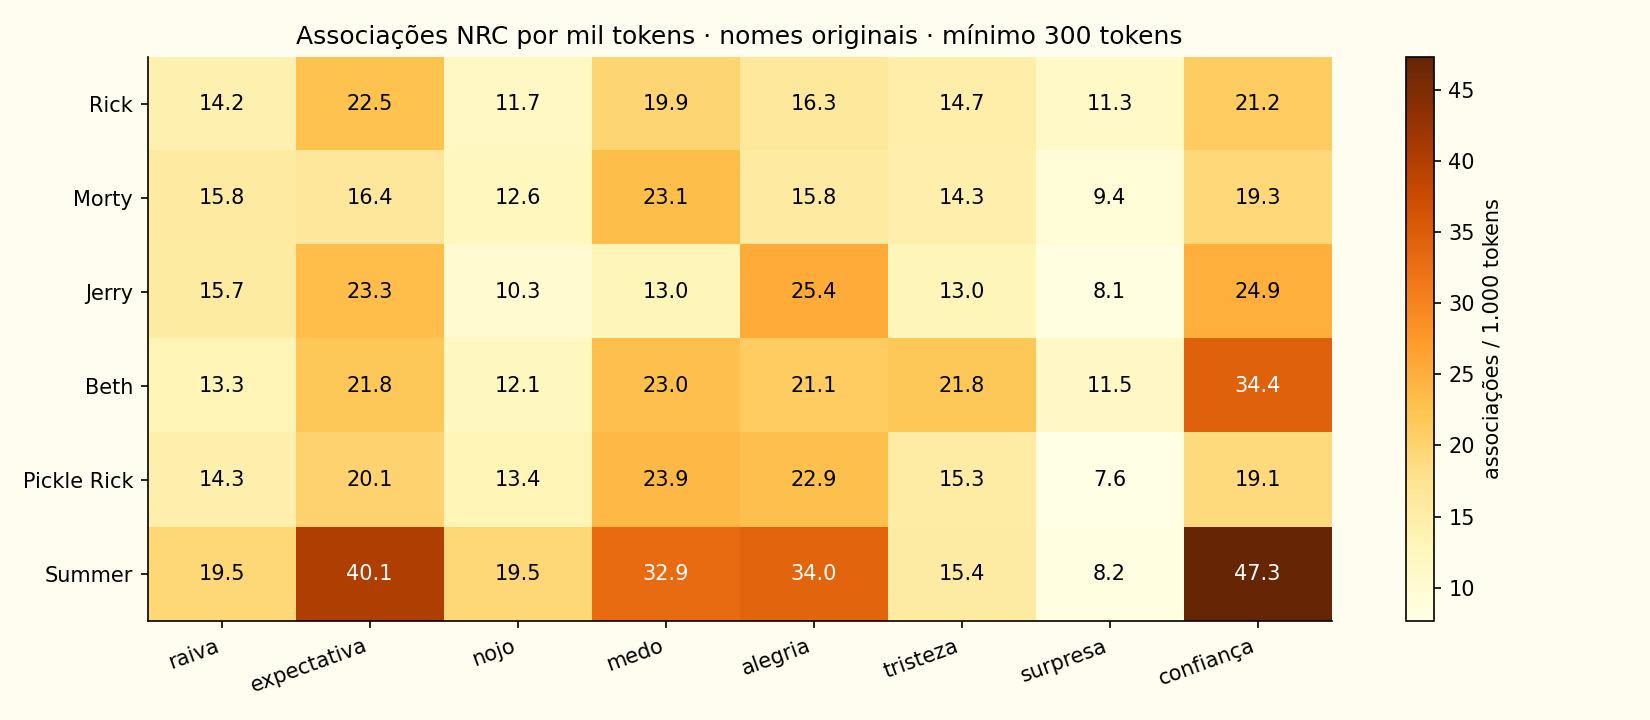

,category,word,occurrences,share_within_emotion
0,anger,shit,30,0.0723
1,anger,hell,26,0.0627
2,anger,bad,24,0.0578
147,anticipation,time,89,0.1488
148,anticipation,good,51,0.0853
149,anticipation,god,48,0.0803
286,disgust,shit,30,0.0929
287,disgust,hell,26,0.0805
288,disgust,bad,24,0.0743
395,fear,god,48,0.0847


In [7]:
display(Image(filename=str(OUTPUT_DIR / "character_emotions.png")))
display(tables["emotion_words"].groupby("category", sort=False).head(3).round(4))

### Uma checagem antes de interpretar

Nesta revisão, examino quanto duas palavras, `god` e `time`, influenciam o NRC. A tabela retira apenas suas contribuições e mantém todos os tokens no denominador. Esse teste é uma análise de sensibilidade, não uma proposta de corrigir o corpus removendo palavras.

In [8]:
display(tables["sensitivity"].loc[tables["sensitivity"]["emotion"].isin(["anticipation", "joy", "fear"])].round(4))

,emotion,baseline_associations,without_selected_associations,baseline_per_1000,without_selected_per_1000,removed_share
1,anticipation,598,461,23.5702,18.1704,0.2291
3,fear,567,519,22.3484,20.4564,0.0847
4,joy,501,453,19.7470,17.8550,0.0958


## 4. Quando os métodos discordam, volto às palavras

Cada índice bruto é a soma dos pontos lexicais ÷ tokens do episódio × 1.000. AFINN mantém os pesos originais; Bing e NRC usam +1/−1. As magnitudes têm unidades de pontuação próprias. O gráfico usa z-score com desvio amostral: acima de zero significa acima da média daquele método neste recorte, mesmo quando o saldo bruto é negativo. A correlação descreve co-variação e não valida contexto.

Ordeno as diferenças entre z-scores para selecionar um episódio para leitura. O diagnóstico usa pelo menos 50 falas para evitar que o menor fragmento determine sozinho a escolha; a tabela de inventário conserva todos os episódios.

,season,episode,n_lines,n_tokens,AFINN_points_per_1000,Bing_points_per_1000,NRC_points_per_1000
0,1,1,241,3870,14.729,9.044,6.718
1,1,2,222,2541,-7.477,8.264,-5.903
2,1,6,71,1005,52.736,19.900,16.915
3,2,1,239,3212,-42.341,-14.321,-11.208
4,2,5,221,2841,0.704,9.856,20.767
5,2,8,73,1041,22.094,12.488,0.000
6,2,10,8,143,-6.993,-20.979,0.000
7,3,1,215,2850,-5.614,-1.053,-5.965
8,3,3,189,2554,-6.265,4.699,-1.566
9,3,4,257,3354,-12.224,0.596,5.069


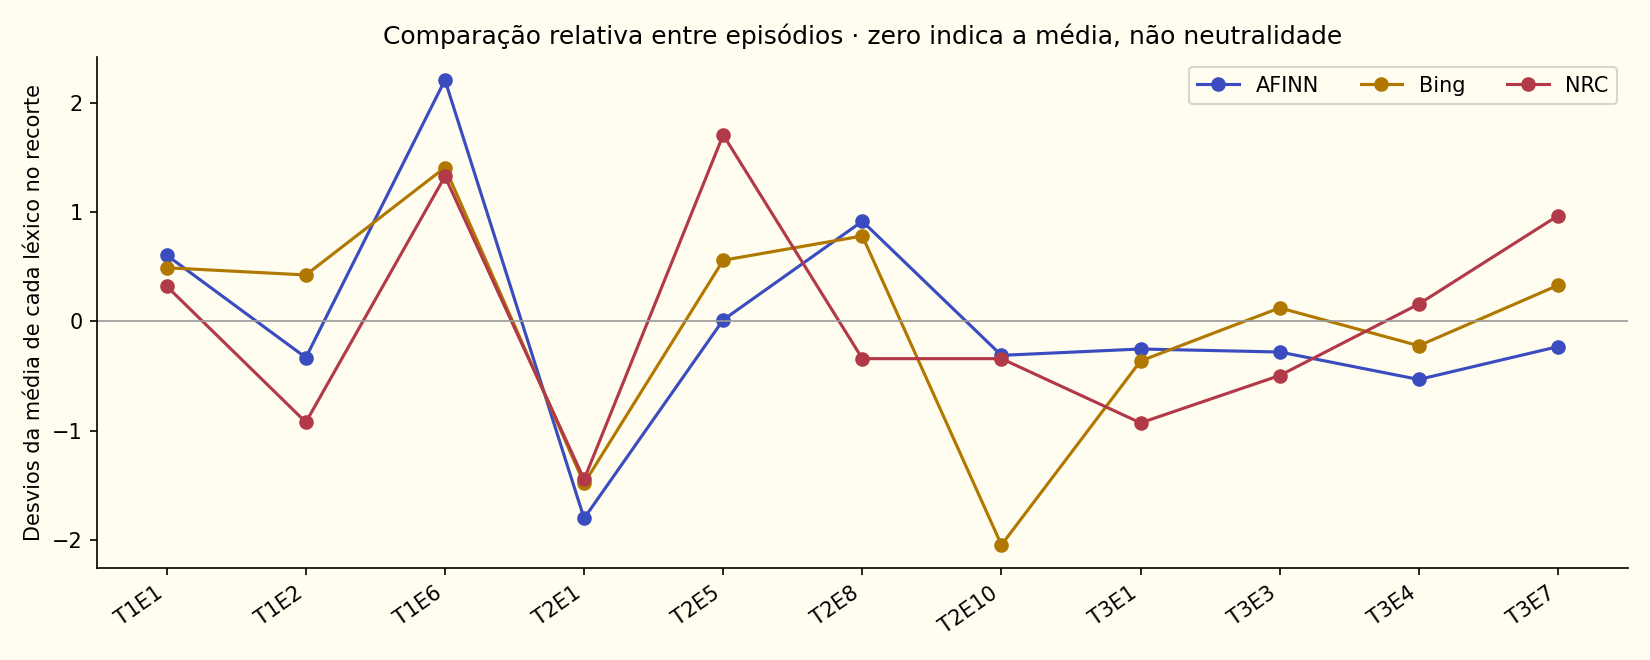

,AFINN,Bing,NRC
AFINN,1.000,0.739,0.591
Bing,0.739,1.000,0.571
NRC,0.591,0.571,1.000


,season,episode,n_lines,n_tokens,AFINN,Bing,NRC,between_lexicon_range
4,2,5,221,2841,0.013,0.558,1.704,1.691
1,1,2,222,2541,-0.331,0.424,-0.923,1.347
5,2,8,73,1041,0.915,0.781,-0.341,1.256


,word,occurrences,word_score,points,lexicon,season,episode,magnitude
3,shit,7,-4.0,-28.0,AFINN,2,5,28.0
1,like,9,2.0,18.0,AFINN,2,5,18.0
15,hell,4,-4.0,-16.0,AFINN,2,5,16.0
13,fuck,4,-4.0,-16.0,AFINN,2,5,16.0
10,love,5,3.0,15.0,AFINN,2,5,15.0
6,disqualified,6,-2.0,-12.0,AFINN,2,5,12.0
228,god,10,1.0,10.0,NRC,2,5,10.0
229,president,9,1.0,9.0,NRC,2,5,9.0
124,like,9,1.0,9.0,Bing,2,5,9.0
125,right,8,1.0,8.0,Bing,2,5,8.0


In [9]:
display(tables["episodes"][["season", "episode", "n_lines", "n_tokens", "AFINN_points_per_1000", "Bing_points_per_1000", "NRC_points_per_1000"]].round(3))
display(Image(filename=str(OUTPUT_DIR / "episode_zscores.png")))
display(tables["episode_zscores"][["AFINN", "Bing", "NRC"]].corr().round(3))
display(tables["divergence_diagnostic"].head(3).round(3))
words = tables["divergent_episode_words"].copy()
words["magnitude"] = words["points"].abs()
display(words.sort_values("magnitude", ascending=False).groupby("lexicon", sort=False).head(6))

## 5. Uma demonstração do limite da abordagem

As frases a seguir são exemplos criados para explicar o método. Elas não pertencem ao corpus nem entram em suas métricas. O baseline soma palavras sem uma regra de negação: incluir `not` não garante inversão de polaridade. Preservar o token é só o primeiro passo para estudar esse problema.

In [10]:
demo = pd.DataFrame({"season no.": [1, 1], "episode no.": [1, 1], "name": ["Exemplo", "Exemplo"],
                     "line": ["This is wonderful.", "This is not wonderful."]})
demo_corpus, _, _, _ = prepare_corpus(demo)
demo_scores = score_lines(demo_corpus, run["lexicons"])
display(demo_scores[["text", "AFINN_score", "Bing_score", "NRC_score"]])

,text,AFINN_score,Bing_score,NRC_score
0,This is wonderful.,4.0,1.0,1.0
1,This is not wonderful.,4.0,1.0,1.0


## Conclusão ligada às evidências

A síntese abaixo é calculada a partir desta execução. As interpretações se referem ao arquivo analisado, aos dicionários e às regras documentadas.

In [11]:
q = run["manifest"]["quality"]
coverage = tables["coverage"].set_index("lexicon")
observed = tables["agreement"].loc[tables["agreement"]["scope"].eq("vocabulario_observado")]
sensitivity = tables["sensitivity"].set_index("emotion")
small = tables["episodes"].nsmallest(1, "n_lines").iloc[0]
format_count = lambda n: f"{n:,}".replace(",", ".")
format_pct = lambda n: f"{n:.1%}".replace(".", ",")
agreement_min, agreement_max = observed["agreement_by_type"].min(), observed["agreement_by_type"].max()
summary = (
    f"Analisei **{format_count(q['retained_lines'])} falas e {format_count(q['tokens'])} tokens**, distribuídos por "
    f"**{len(tables['episodes'])} episódios representados no arquivo**. O menor fragmento, "
    f"T{small['season']}E{small['episode']}, tem {small['n_lines']} falas; por isso o recorte não sustenta uma descrição da série inteira.\n\n"
    f"Os léxicos cobrem de **{format_pct(coverage['token_coverage'].min())} a {format_pct(coverage['token_coverage'].max())}** "
    f"das ocorrências de tokens. Nas palavras de polaridade compartilhadas e observadas, "
    f"o acordo por tipo varia de **{format_pct(agreement_min)} a {format_pct(agreement_max)}**. "
    "Esse acordo descreve os dicionários; não mede acerto na interpretação das falas.\n\n"
    f"Retirar apenas as contribuições de `god` e `time`, mantendo o total de tokens, reduz em "
    f"**{format_pct(sensitivity.loc['anticipation', 'removed_share'])}** as associações de expectativa. "
    "A sensibilidade mostra por que é necessário abrir as palavras antes de atribuir um significado narrativo ao painel.\n\n"
    "O estudo permite comparar vocabulário e escolhas de método neste corpus. "
    "Para avaliar a interpretação de polaridade em contexto, a próxima etapa é rotular uma amostra e comparar "
    "o baseline com negação e um modelo contextual, usando as mesmas falas reservadas para avaliação."
)
display(Markdown(summary.replace("\\n", "\n")))

Analisei **1.905 falas e 25.371 tokens**, distribuídos por **11 episódios representados no arquivo**. O menor fragmento, T2E10, tem 8 falas; por isso o recorte não sustenta uma descrição da série inteira.

Os léxicos cobrem de **7,2% a 9,1%** das ocorrências de tokens. Nas palavras de polaridade compartilhadas e observadas, o acordo por tipo varia de **97,9% a 98,9%**. Esse acordo descreve os dicionários; não mede acerto na interpretação das falas.

Retirar apenas as contribuições de `god` e `time`, mantendo o total de tokens, reduz em **22,9%** as associações de expectativa. A sensibilidade mostra por que é necessário abrir as palavras antes de atribuir um significado narrativo ao painel.

O estudo permite comparar vocabulário e escolhas de método neste corpus. Para avaliar a interpretação de polaridade em contexto, a próxima etapa é rotular uma amostra e comparar o baseline com negação e um modelo contextual, usando as mesmas falas reservadas para avaliação.

## Referências, reprodução e próximos passos

- [Roteiros — fonte Kaggle](https://www.kaggle.com/datasets/isabelgonalves/roteiros-de-rick-and-morty)
- [Léxicos — arquivos utilizados](https://www.kaggle.com/datasets/isabelgonalves/categorizao-de-sentimentos)
- [AFINN — autor](https://github.com/fnielsen/afinn)
- [NRC — autores e condições de uso](https://saifmohammad.com/WebPages/NRC-Emotion-Lexicon.htm)
- [Bing Liu — Opinion Lexicon](https://www.cs.uic.edu/~liub/FBS/sentiment-analysis.html)
- [Estudo completo no Kaggle](https://www.kaggle.com/code/isabelgonalves/an-lise-de-sentimentos)
- [Síntese Portfolio Night](https://www.kaggle.com/code/isabelgonalves/case-portfolio-night-2026-s-o-paulo)

As tabelas e figuras são exportadas para a pasta indicada na execução; o manifesto registra as entradas e as versões do ambiente. As saídas visíveis também ficam incorporadas neste notebook. A normalização dos apóstrofos altera os tokens da v4: o mesmo corpus passa de 25.599 para 25.371 tokens. Valores de cobertura e taxas devem ser recalculados.

**Extensões ainda não executadas:** anotação humana, separação entre desenvolvimento e avaliação, tratamento explícito de negação e comparação com modelo contextual. Esta entrega também não faz inferência estatística nem valida as oito emoções contra rótulos humanos.